#Assignment 2

Max collaborators = 3

Hand holding is low for this assignment. Adjust accordingly. In case of confusion, feel free to reach out to your lab faculties. Good luck.

In [1]:
COLLABORATORS_NAME = "Muaz Ibne Ashraf"
COLLABORATORS_ID = "21101177"

#Loading dependencies

In [2]:
import numpy as np
from tensorflow import keras
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

#Loading dataset

In [3]:
id = 21101177

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train, y_train = sklearn.utils.resample(x_train, y_train, replace = False, n_samples = 5000, random_state = id, stratify = y_train)
x_test, y_test = sklearn.utils.resample(x_test, y_test, replace = False, n_samples = 1000, random_state = id, stratify = y_test)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
y_train = y_train.ravel()
y_test = y_test.ravel()

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
(5000, 32, 32, 3) (5000,)
(1000, 32, 32, 3) (1000,)


#Task 1: Training a logistic regressor [10 Marks]

###1. Convert the images to grayscale

(5000, 32, 32)
(1000, 32, 32)


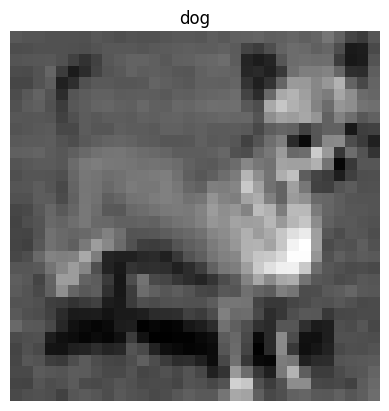

In [4]:
# CIFAR-10 images are RGB. Average the 3 channels to convert them to grayscale.
x_train_gray = np.mean(x_train, axis = 3)
x_test_gray = np.mean(x_test, axis = 3)

print(x_train_gray.shape)
print(x_test_gray.shape)

plt.imshow(x_train_gray[0], cmap = 'gray')
plt.title(class_names[y_train[0]])
plt.axis('off')
plt.show()

### 2. Prepare the grayscale images for logistic regressor (reshape and normalize)

Use z-score normalization.

In [5]:
# Reshape: each 32 x 32 image becomes one row with 1024 features.
x_train_gray_flat = x_train_gray.reshape(x_train_gray.shape[0], -1)
x_test_gray_flat = x_test_gray.reshape(x_test_gray.shape[0], -1)

# Z-score normalization using train mean and train standard deviation.
mean = np.mean(x_train_gray_flat, axis = 0)
std = np.std(x_train_gray_flat, axis = 0)
std[std == 0] = 1

x_train_gray_z = (x_train_gray_flat - mean) / std
x_test_gray_z = (x_test_gray_flat - mean) / std

print(x_train_gray_z.shape)
print(x_test_gray_z.shape)

(5000, 1024)
(1000, 1024)


###3. Create a validation set (20%)

In [6]:
x_train_lr, x_val_lr, y_train_lr, y_val_lr = train_test_split(
    x_train_gray_z,
    y_train,
    test_size = 0.20,
    random_state = id,
    stratify = y_train
)

print(x_train_lr.shape, y_train_lr.shape)
print(x_val_lr.shape, y_val_lr.shape)

(4000, 1024) (4000,)
(1000, 1024) (1000,)


###4. Compute class weights

Go through this link - https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html

In [7]:
classes = np.unique(y_train_lr)
weights = compute_class_weight(class_weight = 'balanced', classes = classes, y = y_train_lr)
class_weights_lr = dict(zip(classes, weights))

print(class_weights_lr)

{np.uint8(0): np.float64(1.0), np.uint8(1): np.float64(1.0), np.uint8(2): np.float64(1.0), np.uint8(3): np.float64(1.0), np.uint8(4): np.float64(1.0), np.uint8(5): np.float64(1.0), np.uint8(6): np.float64(1.0), np.uint8(7): np.float64(1.0), np.uint8(8): np.float64(1.0), np.uint8(9): np.float64(1.0)}


###5. Run the logistic regressor

Use L2 regularizer. Find the C hyperparameter value through grid search. Pick the testing values according to your understanding. Use at least 3 test values and at max 5. Use the computed class weights while training your model.

In [8]:
c_values = [0.01, 0.1, 1.0]
best_c = None
best_val_accuracy = 0
best_lr_model = None

for c in c_values:
    model = LogisticRegression(
        penalty = 'l2',
        C = c,
        class_weight = class_weights_lr,
        max_iter = 1000,
        solver = 'lbfgs',
        multi_class = 'auto'
    )
    model.fit(x_train_lr, y_train_lr)
    y_val_pred = model.predict(x_val_lr)
    val_accuracy = accuracy_score(y_val_lr, y_val_pred)
    print('C =', c, 'Validation accuracy =', val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_c = c
        best_lr_model = model

print('Best C:', best_c)
print('Best validation accuracy:', best_val_accuracy)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C = 0.01 Validation accuracy = 0.261


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C = 0.1 Validation accuracy = 0.214


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


C = 1.0 Validation accuracy = 0.193
Best C: 0.01
Best validation accuracy: 0.261


###6. Evaluate the logistic regressor on the test set

In [9]:
y_test_pred_lr = best_lr_model.predict(x_test_gray_z)

print('Logistic Regression Test Accuracy:', accuracy_score(y_test, y_test_pred_lr))
print(classification_report(y_test, y_test_pred_lr, target_names = class_names))

Logistic Regression Test Accuracy: 0.257
              precision    recall  f1-score   support

    airplane       0.26      0.31      0.28       100
  automobile       0.33      0.27      0.30       100
        bird       0.18      0.14      0.16       100
         cat       0.18      0.15      0.16       100
        deer       0.16      0.16      0.16       100
         dog       0.25      0.26      0.26       100
        frog       0.22      0.24      0.23       100
       horse       0.24      0.25      0.24       100
        ship       0.38      0.41      0.39       100
       truck       0.33      0.38      0.36       100

    accuracy                           0.26      1000
   macro avg       0.25      0.26      0.25      1000
weighted avg       0.25      0.26      0.25      1000



###7. Write code to pick up a random image from the test set and display it

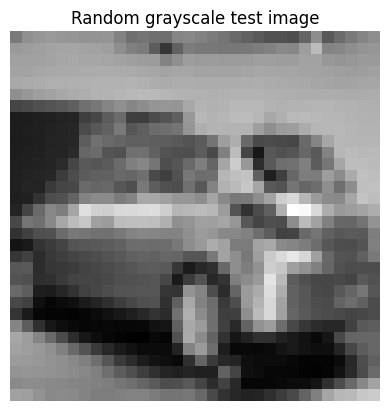

In [10]:
random_index_lr = np.random.randint(0, x_test_gray.shape[0])

plt.imshow(x_test_gray[random_index_lr], cmap = 'gray')
plt.title('Random grayscale test image')
plt.axis('off')
plt.show()

###8. Print the predicted class vs the original class

Do not print out the numerical class. Map it from here - https://keras.io/2/api/datasets/cifar10/

In [11]:
predicted_class_lr = class_names[y_test_pred_lr[random_index_lr]]
original_class_lr = class_names[y_test[random_index_lr]]

print('Predicted class:', predicted_class_lr)
print('Original class:', original_class_lr)

Predicted class: automobile
Original class: automobile


#Task 2: Training a convolutional neural network [20 Marks]

We will not strictly control how you implement this code. You can use either Tensorflow or PyTorch. However the structure of the network must be -

```
Input -> Conv1 -> Conv2 -> Conv3 -> Fully Connected 1 -> Fully Connected 2 -> Output
```

Use activation functions and pooling as you want. Feel free to adjust dimensions as you need. Set the hyperparameters yourself. Use a maximum learning rate of 0.01 and a maximum epoch number of 100. Use AdamW as optimizer.

**Try achieving good accuracy. There are marks for that.**

###1. Train the model on grayscale images

You do not need to use the validation set. Train on the initial train set. Recalculate the class weights again and pass it to the optimizer function. Normalize the images before processing.

In [12]:
# Normalize grayscale images for CNN.
x_train_gray_cnn = x_train_gray / 255.0
x_test_gray_cnn = x_test_gray / 255.0

# CNN needs channel dimension: (samples, height, width, channel)
x_train_gray_cnn = x_train_gray_cnn.reshape(-1, 32, 32, 1)
x_test_gray_cnn = x_test_gray_cnn.reshape(-1, 32, 32, 1)

classes = np.unique(y_train)
weights = compute_class_weight(class_weight = 'balanced', classes = classes, y = y_train)
class_weights_cnn = dict(zip(classes, weights))

model_gray = keras.Sequential([
    keras.layers.Input(shape = (32, 32, 1)),
    keras.layers.Conv2D(32, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(128, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation = 'relu'),
    keras.layers.Dense(64, activation = 'relu'),
    keras.layers.Dense(10, activation = 'softmax')
])

model_gray.compile(
    optimizer = keras.optimizers.AdamW(learning_rate = 0.001),
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

model_gray.summary()

history_gray = model_gray.fit(
    x_train_gray_cnn,
    y_train,
    epochs = 20,
    batch_size = 64,
    class_weight = class_weights_cnn,
    verbose = 1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 363,850 (1.39 MB)

 Trainable params: 363,850 (1.39 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 144ms/step - accuracy: 0.1586 - loss: 2.2249
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 159ms/step - accuracy: 0.2914 - loss: 1.9354
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 155ms/step - accuracy: 0.3738 - loss: 1.7284
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 153ms/step - accuracy: 0.4256 - loss: 1.5947
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 154ms/step - accuracy: 0.4750 - loss: 1.4700
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 145ms/step - accuracy: 0.5204 - loss: 1.3504
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 145ms/step - accuracy: 0.5396 - loss: 1.2884
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 153ms/step - accuracy: 0.5744 - loss: 1.1988
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 155ms/step - accuracy: 0.6088 - loss: 1.1203
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 155ms/step - accuracy: 0.6286 - loss: 1.0392
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 155ms/step - accuracy: 0.6630 - loss: 0.9538
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12

###2. Evaluate the model on the grayscale test set

In [13]:
gray_test_loss, gray_test_accuracy = model_gray.evaluate(x_test_gray_cnn, y_test, verbose = 0)
print('Grayscale CNN Test Loss:', gray_test_loss)
print('Grayscale CNN Test Accuracy:', gray_test_accuracy)

Grayscale CNN Test Loss: 1.7734025716781616
Grayscale CNN Test Accuracy: 0.5640000104904175


###3. Write code to pick up a random image from the test set and display it

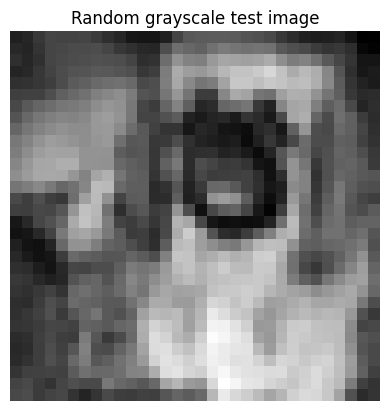

In [14]:
random_index_gray_cnn = np.random.randint(0, x_test_gray_cnn.shape[0])

plt.imshow(x_test_gray_cnn[random_index_gray_cnn].reshape(32, 32), cmap = 'gray')
plt.title('Random grayscale test image')
plt.axis('off')
plt.show()

###4. Print the predicted class vs the original class

In [15]:
gray_prediction = model_gray.predict(x_test_gray_cnn[random_index_gray_cnn].reshape(1, 32, 32, 1))
gray_predicted_class = class_names[np.argmax(gray_prediction)]
gray_original_class = class_names[y_test[random_index_gray_cnn]]

print('Predicted class:', gray_predicted_class)
print('Original class:', gray_original_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Predicted class: dog
Original class: dog


###5. Train the model on the RGB images

Keep the model same.

In [16]:
# Normalize RGB images.
x_train_rgb_cnn = x_train / 255.0
x_test_rgb_cnn = x_test / 255.0

model_rgb = keras.Sequential([
    keras.layers.Input(shape = (32, 32, 3)),
    keras.layers.Conv2D(32, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(128, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation = 'relu'),
    keras.layers.Dense(64, activation = 'relu'),
    keras.layers.Dense(10, activation = 'softmax')
])

model_rgb.compile(
    optimizer = keras.optimizers.AdamW(learning_rate = 0.001),
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

model_rgb.summary()

history_rgb = model_rgb.fit(
    x_train_rgb_cnn,
    y_train,
    epochs = 20,
    batch_size = 64,
    class_weight = class_weights_cnn,
    verbose = 1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 364,426 (1.39 MB)

 Trainable params: 364,426 (1.39 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 147ms/step - accuracy: 0.2238 - loss: 2.0911
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 22s 164ms/step - accuracy: 0.3632 - loss: 1.7225
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 160ms/step - accuracy: 0.4208 - loss: 1.5609
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 156ms/step - accuracy: 0.4898 - loss: 1.4180
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 151ms/step - accuracy: 0.5202 - loss: 1.3276
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 147ms/step - accuracy: 0.5512 - loss: 1.2292
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 21s 161ms/step - accuracy: 0.5744 - loss: 1.1648
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 158ms/step - accuracy: 0.6126 - loss: 1.0695
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 149ms/step - accuracy: 0.6412 - loss: 1.0002
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 21s 158ms/step - accuracy: 0.6716 - loss: 0.9235
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 158ms/step - accuracy: 0.7072 - loss: 0.8267
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 20

###6. Evaluate the model on the RGB images

In [17]:
rgb_test_loss, rgb_test_accuracy = model_rgb.evaluate(x_test_rgb_cnn, y_test, verbose = 0)
print('RGB CNN Test Loss:', rgb_test_loss)
print('RGB CNN Test Accuracy:', rgb_test_accuracy)

RGB CNN Test Loss: 1.7533103227615356
RGB CNN Test Accuracy: 0.5920000076293945


###7. Write code to pick up a random image from the test set and display it

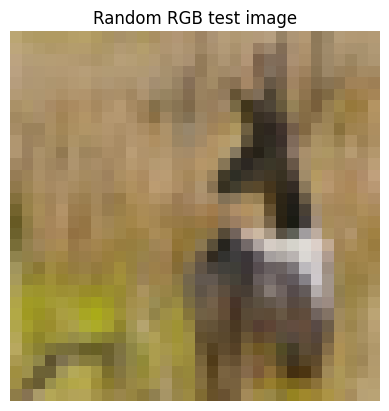

In [18]:
random_index_rgb_cnn = np.random.randint(0, x_test_rgb_cnn.shape[0])

plt.imshow(x_test_rgb_cnn[random_index_rgb_cnn])
plt.title('Random RGB test image')
plt.axis('off')
plt.show()

###8. Print the predicted class vs the original class

In [19]:
rgb_prediction = model_rgb.predict(x_test_rgb_cnn[random_index_rgb_cnn].reshape(1, 32, 32, 3))
rgb_predicted_class = class_names[np.argmax(rgb_prediction)]
rgb_original_class = class_names[y_test[random_index_rgb_cnn]]

print('Predicted class:', rgb_predicted_class)
print('Original class:', rgb_original_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
Predicted class: bird
Original class: deer


###9. Add one more conv layer and check if it increases the performance for the RGB images

In [20]:
model_rgb_extra = keras.Sequential([
    keras.layers.Input(shape = (32, 32, 3)),
    keras.layers.Conv2D(32, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(128, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.Conv2D(128, (3, 3), activation = 'relu', padding = 'same'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation = 'relu'),
    keras.layers.Dense(64, activation = 'relu'),
    keras.layers.Dense(10, activation = 'softmax')
])

model_rgb_extra.compile(
    optimizer = keras.optimizers.AdamW(learning_rate = 0.001),
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

model_rgb_extra.summary()

history_rgb_extra = model_rgb_extra.fit(
    x_train_rgb_cnn,
    y_train,
    epochs = 20,
    batch_size = 64,
    class_weight = class_weights_cnn,
    verbose = 1
)

rgb_extra_test_loss, rgb_extra_test_accuracy = model_rgb_extra.evaluate(x_test_rgb_cnn, y_test, verbose = 0)
print('RGB CNN with one extra Conv layer Test Loss:', rgb_extra_test_loss)
print('RGB CNN with one extra Conv layer Test Accuracy:', rgb_extra_test_accuracy)

if rgb_extra_test_accuracy > rgb_test_accuracy:
    print('Adding one more convolution layer increased the performance.')
else:
    print('Adding one more convolution layer did not increase the performance.')

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 512,010 (1.95 MB)

 Trainable params: 512,010 (1.95 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 24s 266ms/step - accuracy: 0.2252 - loss: 2.0587
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 21s 258ms/step - accuracy: 0.3388 - loss: 1.7765
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 22s 274ms/step - accuracy: 0.3944 - loss: 1.6296
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 21s 259ms/step - accuracy: 0.4546 - loss: 1.4902
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 40s 254ms/step - accuracy: 0.4858 - loss: 1.4146
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 22s 275ms/step - accuracy: 0.5206 - loss: 1.3054
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 258ms/step - accuracy: 0.5578 - loss: 1.1967
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 21s 270ms/step - accuracy: 0.5858 - loss: 1.1416
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 40s 259ms/step - accuracy: 0.6220 - loss: 1.0326
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 41s 256ms/step - accuracy: 0.6556 - loss: 0.9499
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 22s 273ms/step - accuracy: 0.6964 - loss: 0.8398
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 41

###10. Use the next markup to write down your observations and reasonings on the performances of the models

Observations -

1. Logistic regression works on flattened grayscale images, so it loses the 2D spatial structure of the image. For this reason its accuracy is usually lower than the CNN models.
2. The grayscale CNN performs better than logistic regression because the convolution layers can learn local patterns from the image.
3. The RGB CNN should perform better than the grayscale CNN in most runs because RGB images keep color information, which is useful for CIFAR-10 classes.
4. Adding one more convolution layer may improve performance if it learns useful extra features. However, if the dataset is small or the training time is limited, the improvement may be small or it may overfit.
5. The final decision should be made from the printed test accuracies above.